# 01 — Exploratory Data Analysis & Business Understanding

This notebook inspects the raw **IBM Telco Customer Churn** dataset, validates data quality (missing values, blank `TotalCharges`, duplicates, outliers), quantifies class imbalance, and highlights the most churn-vulnerable customer segments.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import numpy as np
from IPython.display import Image, display
from src.data_processing import load_raw_data, inspect_raw_data, clean_data, compute_eda_summary
from src.config import FIGURES_DIR

raw_df = load_raw_data()
quality = inspect_raw_data(raw_df)
print('Raw Shape:', raw_df.shape)
print('Duplicates:', quality['duplicate_rows'])
print('Blank TotalCharges:', quality['blank_total_charges_count'])
raw_df.head()

Raw Shape: (7043, 21)
Duplicates: 0
Blank TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Inspect rows where TotalCharges is blank
blank_mask = raw_df['TotalCharges'].astype(str).str.strip().eq('')
raw_df.loc[blank_mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [3]:
# Clean dataset deterministically (tenure == 0 -> TotalCharges = 0.0) and inspect target imbalance
clean_df = clean_data(raw_df, include_target=True)
summary = compute_eda_summary(raw_df, clean_df)
print('Target Distribution:', summary['target_distribution'])
print('Measured Billing Metrics:', summary['measured_billing_metrics'])
print('Numeric Summary:')
pd.DataFrame(summary['numeric_summary']).T

Target Distribution: {'total_customers': 7043, 'churned_customers': 1869, 'retained_customers': 5174, 'churn_rate': 0.2654, 'retention_rate': 0.7346, 'imbalance_ratio_no_to_yes': 2.77}
Measured Billing Metrics: {'total_monthly_charges_sum': 456116.6, 'churned_monthly_charges_sum': 139130.85, 'churned_monthly_charges_share': 0.305, 'avg_monthly_charge_all': 64.76, 'avg_monthly_charge_churned': 74.44, 'avg_monthly_charge_retained': 61.27}
Numeric Summary:


,mean,median,std,min,q25,q75,max,iqr_outlier_count,mean_churned,mean_retained
tenure,32.37,29.00,24.56,0.00,9.00,55.00,72.00,0.0,17.98,37.57
MonthlyCharges,64.76,70.35,30.09,18.25,35.50,89.85,118.75,0.0,74.44,61.27
TotalCharges,2279.73,1394.55,2266.79,0.00,398.55,3786.60,8684.80,0.0,1531.80,2549.91


In [4]:
# Display Churn by Key Segments
for seg_key in ['Contract', 'tenure_bucket', 'PaymentMethod', 'InternetService', 'TechSupport']:
    print(f'\n=== Churn by {seg_key} ===')
    display(pd.DataFrame(summary['segment_analysis'][seg_key]))


=== Churn by Contract ===


,segment,customers,churned,churn_rate,avg_monthly_charges,avg_tenure
0,Month-to-month,3875,1655,0.4271,66.40,18.04
1,One year,1473,166,0.1127,65.05,42.04
2,Two year,1695,48,0.0283,60.77,56.74



=== Churn by tenure_bucket ===


,segment,customers,churned,churn_rate,avg_monthly_charges,avg_tenure
0,0-12 months,2186,1037,0.4744,56.10,4.73
1,13-24 months,1024,294,0.2871,61.36,18.35
2,25-48 months,1594,325,0.2039,65.93,36.19
3,49-72 months,2239,213,0.0951,73.95,63.05



=== Churn by PaymentMethod ===


,segment,customers,churned,churn_rate,avg_monthly_charges,avg_tenure
0,Electronic check,2365,1071,0.4529,76.26,25.17
1,Mailed check,1612,308,0.1911,43.92,21.83
2,Bank transfer (automatic),1544,258,0.1671,67.19,43.66
3,Credit card (automatic),1522,232,0.1524,66.51,43.27



=== Churn by InternetService ===


,segment,customers,churned,churn_rate,avg_monthly_charges,avg_tenure
0,Fiber optic,3096,1297,0.4189,91.50,32.92
1,DSL,2421,459,0.1896,58.10,32.82
2,No,1526,113,0.0740,21.08,30.55



=== Churn by TechSupport ===


,segment,customers,churned,churn_rate,avg_monthly_charges,avg_tenure
0,No,3473,1446,0.4164,74.59,25.84
1,Yes,2044,310,0.1517,80.68,44.82
2,No internet service,1526,113,0.0740,21.08,30.55


01_churn_distribution.png


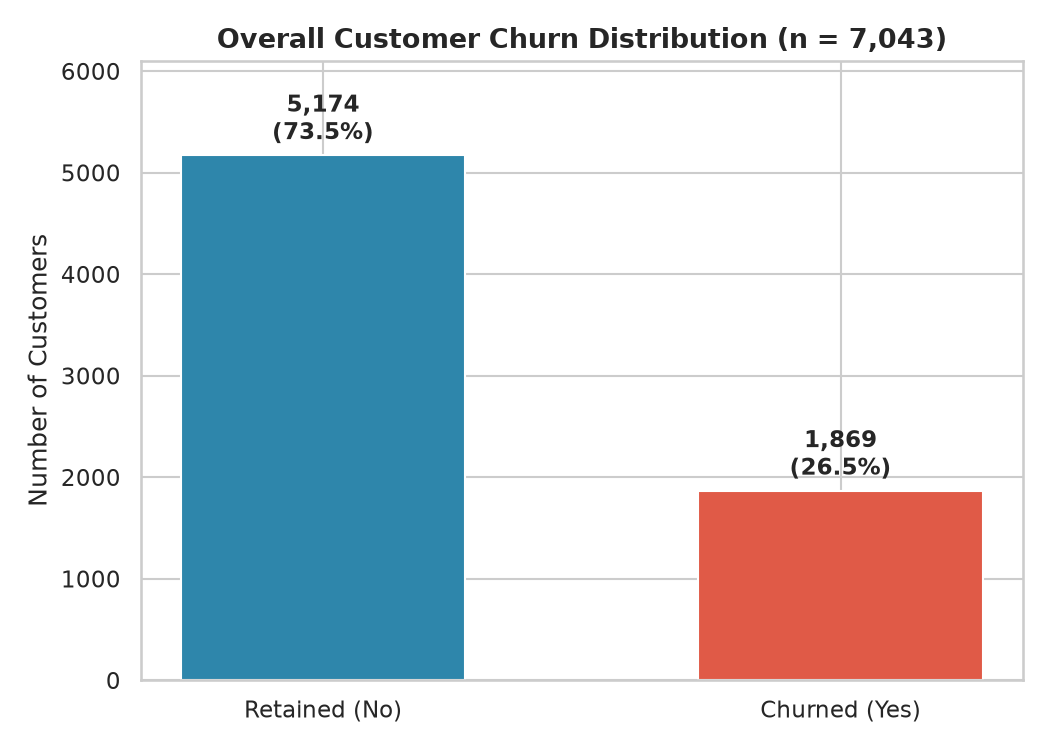

02_churn_by_contract.png


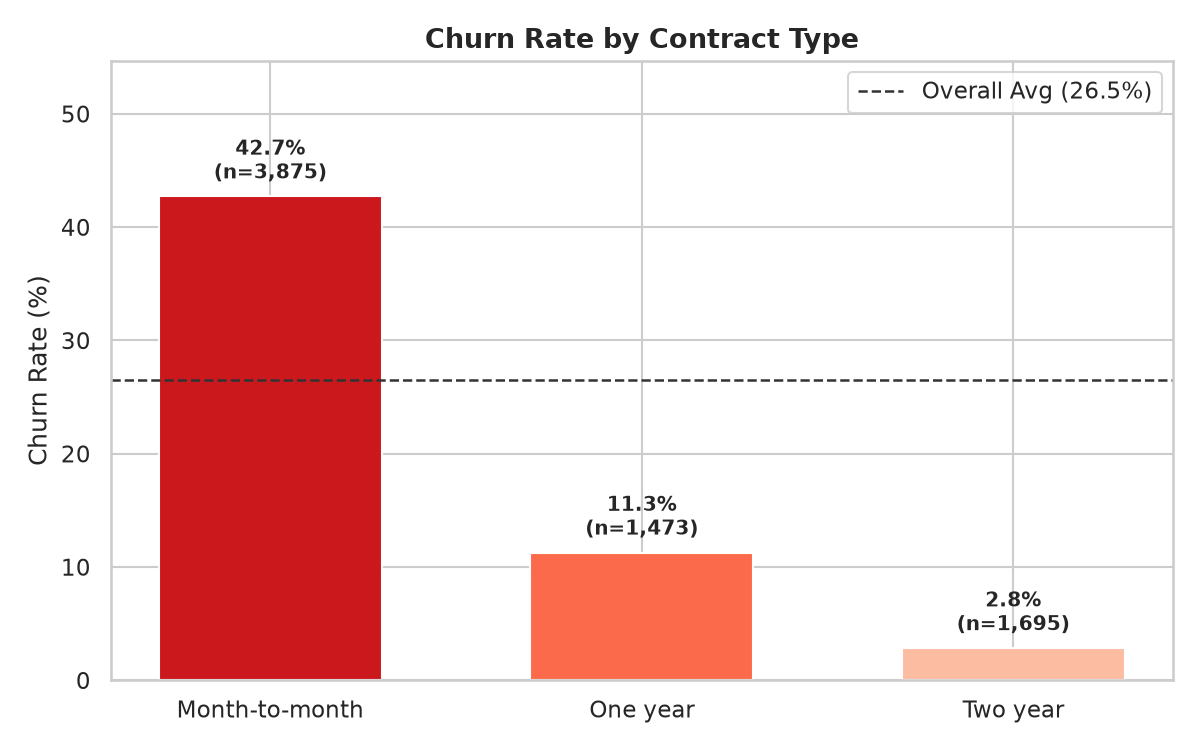

03_churn_by_tenure.png


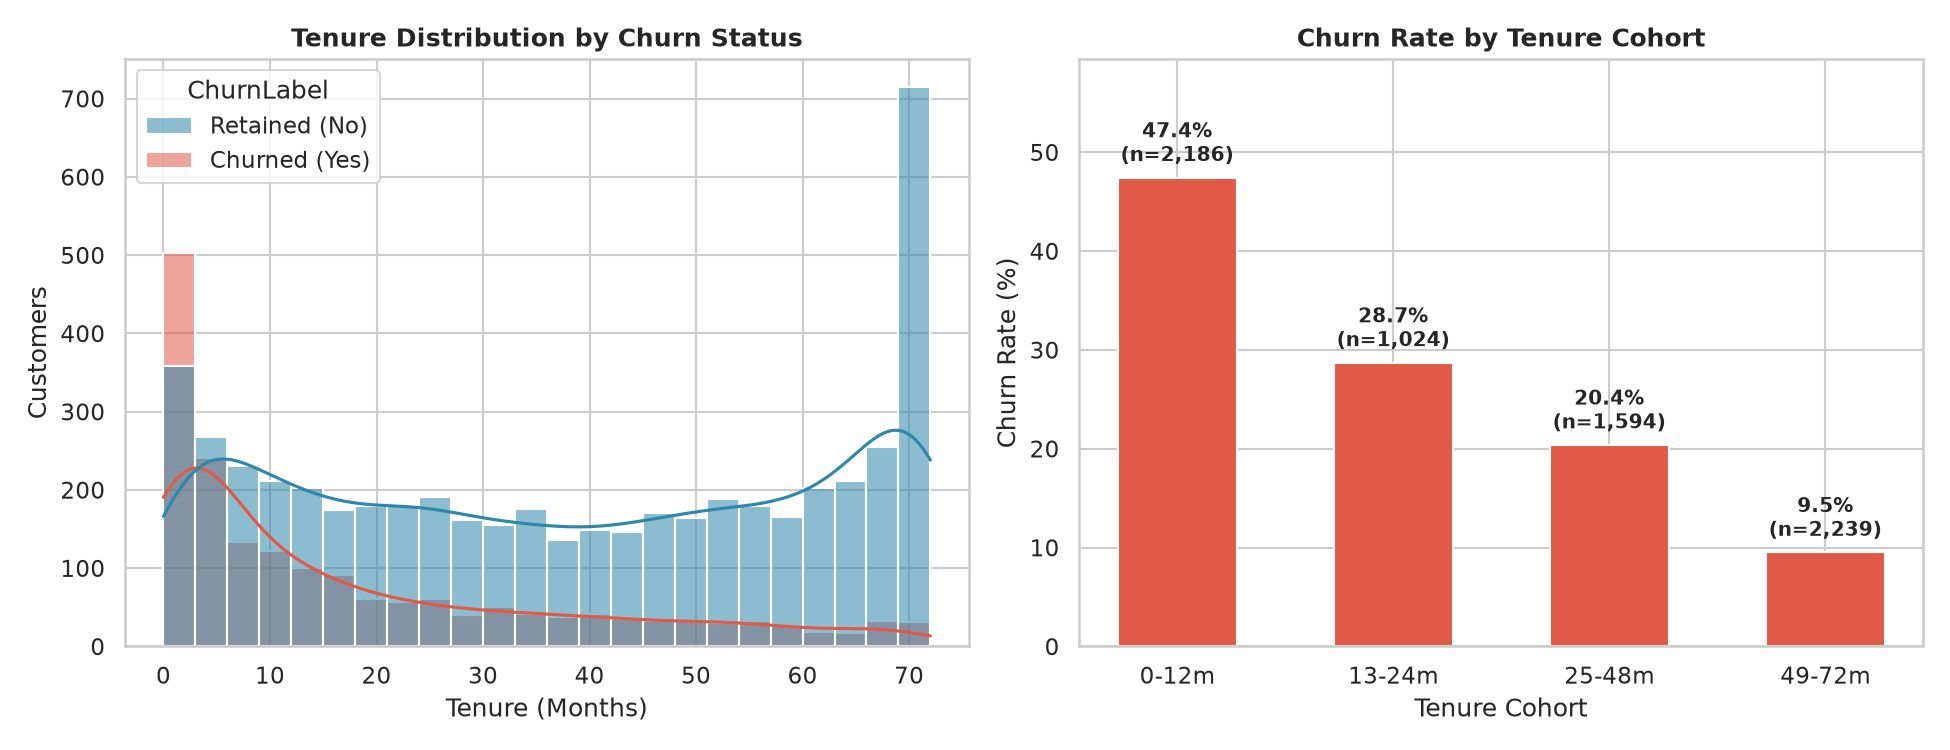

04_churn_by_monthly_charges.png


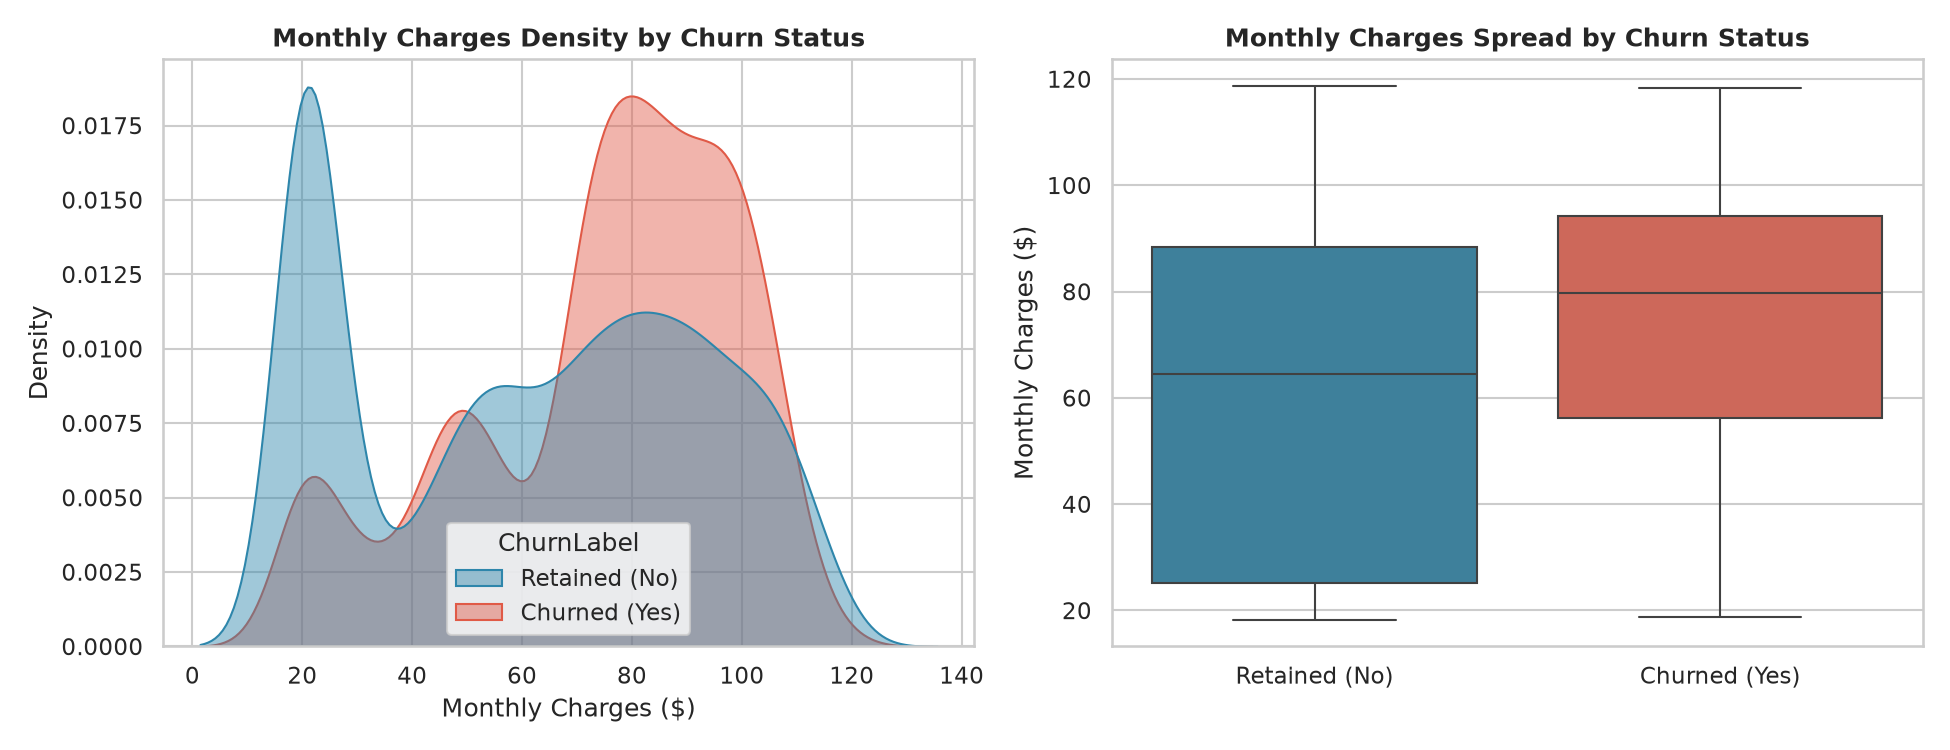

05_churn_by_payment_method.png


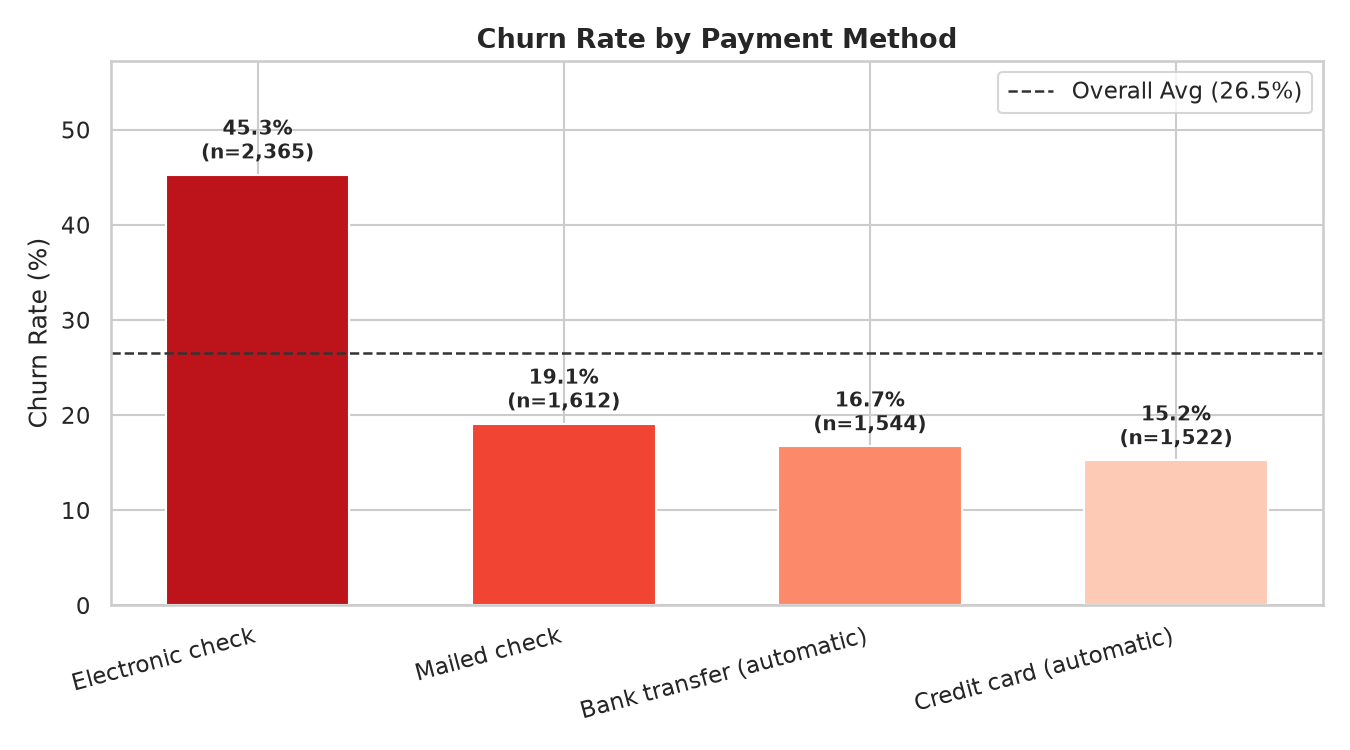

06_churn_by_internet_service.png


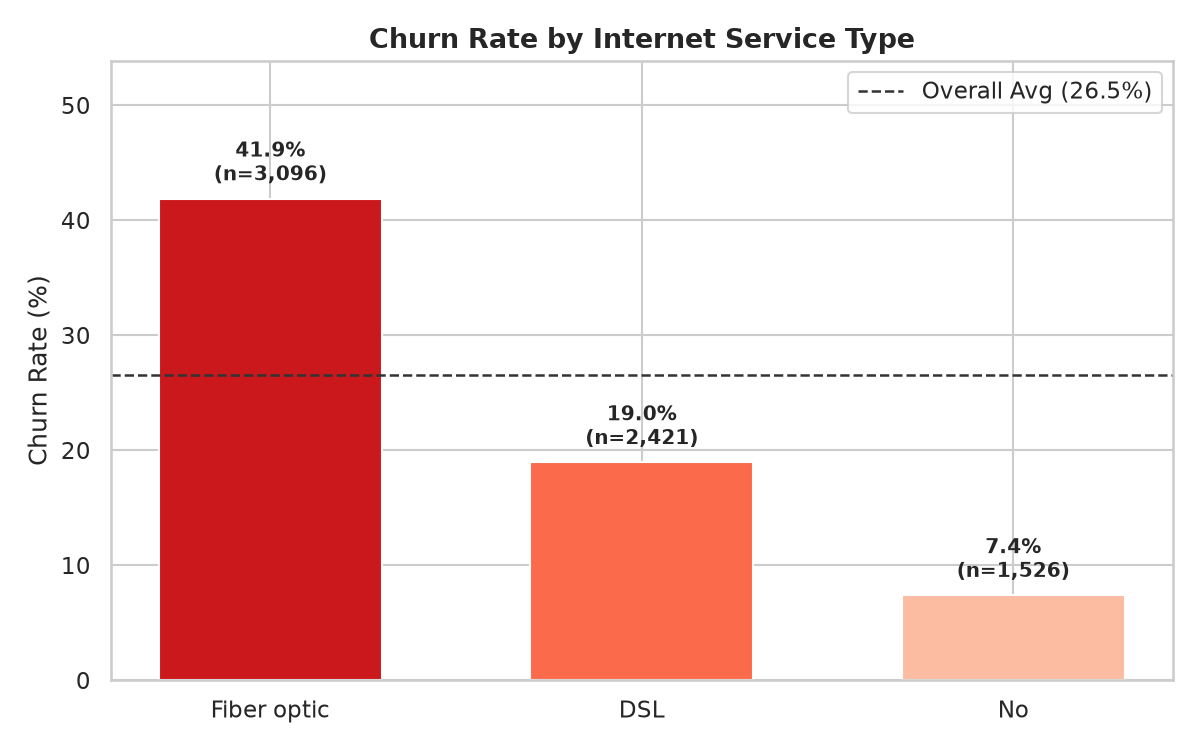

07_churn_by_demographics_and_services.png


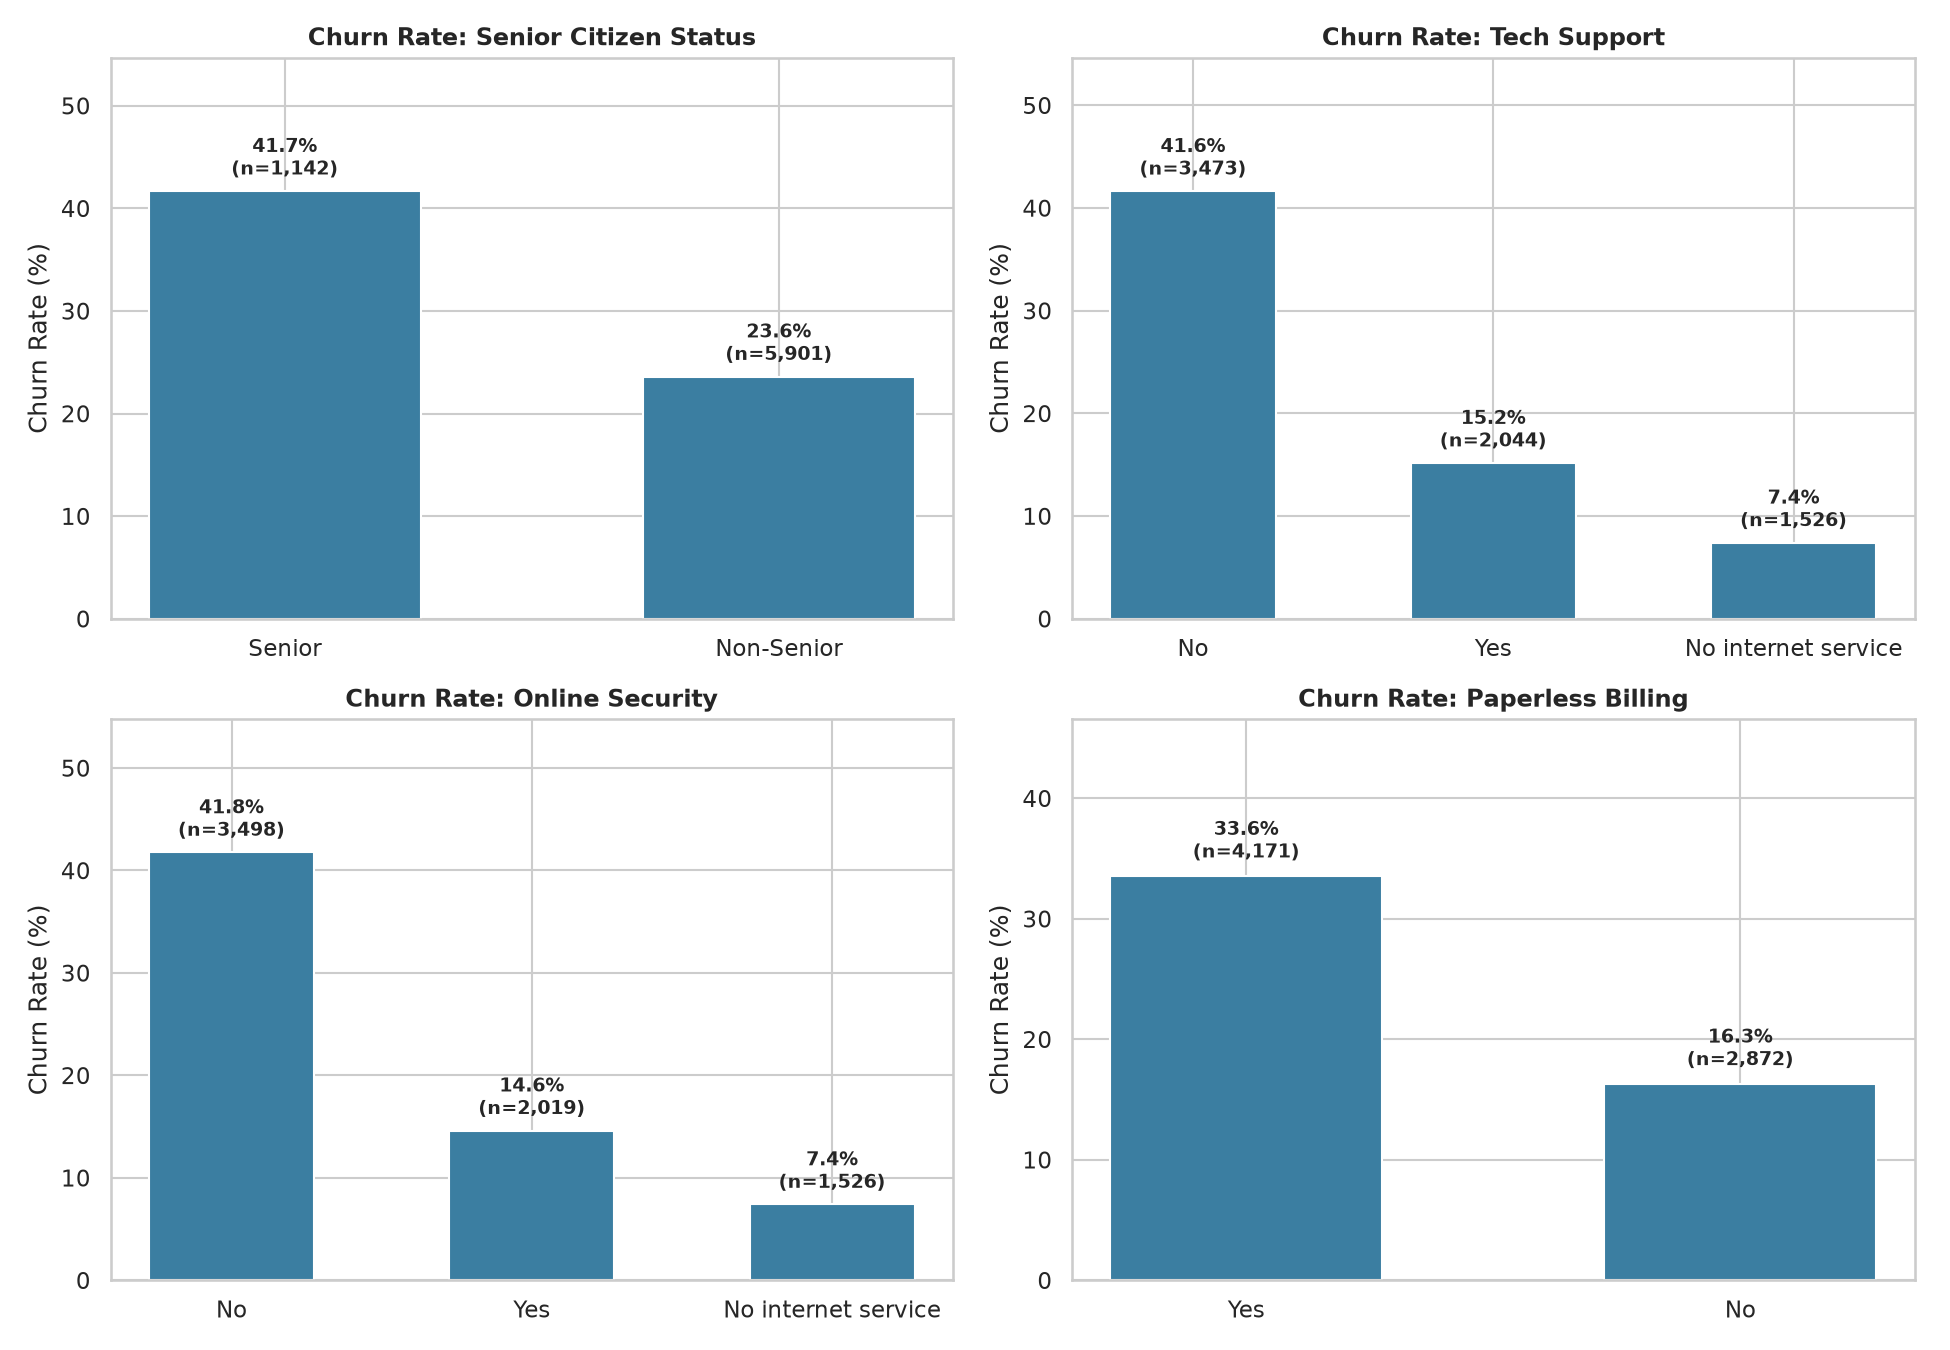

08_numeric_correlation_and_outliers.png


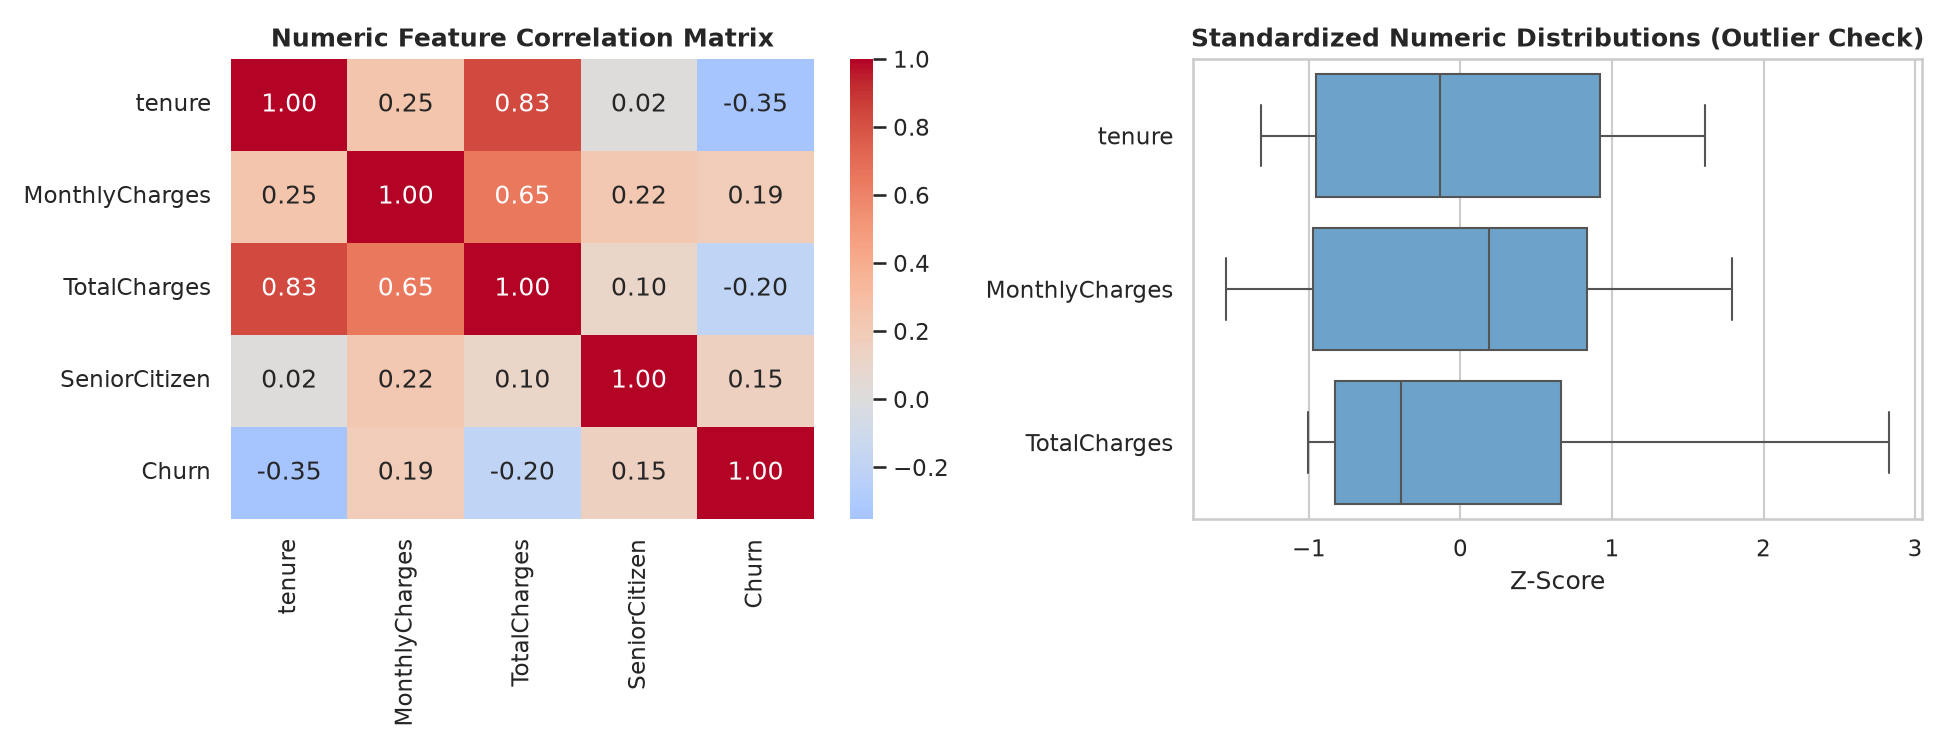

In [5]:
# Display generated EDA figures
for fname in sorted(p.name for p in FIGURES_DIR.glob('0[1-8]_*.png')):
    print(fname)
    display(Image(filename=str(FIGURES_DIR / fname), width=750))

## Key Business Takeaways
- **Class Imbalance**: ~26.5% churn rate (approx. 2.77:1 retained-to-churned ratio). Accuracy alone is not a reliable metric.
- **Highest-Risk Segments**: Month-to-month contracts, 0–12 month tenure customers, Fiber optic internet subscribers, Electronic check payers, and accounts without Tech Support / Online Security.
- **Measured Revenue Exposure vs. Assumptions**: Churned accounts represent a disproportionately higher share of monthly charges due to higher average monthly bills. Actual ROI of retention offers depends on company-specific acquisition cost, gross margin, and offer lift (which must be measured via controlled retention experiments).